# Comparing two models on a gene

Any two `CMEModel`s fitted to the same gene can be compared. When one model **nests** the
other, `compare_nested_models` embeds the small fit in the big model's parameter space, fits
the big model from there, and reports a likelihood-ratio test; `embed=None` uses the nestings
monod knows. When neither nests the other, `compare_models` takes both fitted optima and
reports AIC, BIC and Vuong's test. This notebook shows both on simulated data and on a panel
of 40 real genes, with the question that motivates the machinery: *is this gene's
transcription bursty?*

| Function | Question | Statistic |
|---|---|---|
| `nesting_embedding(small, big)` | Is `small` a point of `big`'s parameter space, and where? | the map, or a `ValueError` saying why not |
| `compare_nested_models(small, big, embed, x_small, ...)` | Does the big model fit better than its nested warm start? | likelihood ratio, chi-square p, score test, AIC/BIC |
| `compare_models(a, b, x_a, x_b, ...)` | Which of two unrelated fits describes the cells better? | Vuong z and p, AIC/BIC |

**Runtime:** about ten minutes with eight cores; sections 4 and 5 fit 40 genes several times.
The panel needs `example_h5ad/gaba_example.h5ad` from the
[monod_examples](https://github.com/pachterlab/monod_examples) repository, as in
`reaction_networks.ipynb`.

In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))

In [2]:
import time, warnings, functools, zlib
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad
import scipy.optimize

from monod.cme_toolbox import CMEModel, _HAS_RUST
from monod.analysis import nesting_embedding, compare_nested_models, compare_models
from monod import chromatin_fit as cf
import monod.inference as inference_module
from monod.inference import perform_inference, search_result_from_uns, searchdata_from_adata

warnings.filterwarnings('ignore')
inference_module.tqdm = functools.partial(inference_module.tqdm, disable=True)   # no progress bars in the saved notebook
os.makedirs('figures', exist_ok=True)
N_CORES = 8
print(f'Rust backend: {_HAS_RUST}')

def dense(hist, limits):
    # the histogram (coords, freqs) as a dense array on the grid
    coords, freqs = hist
    H = np.zeros([int(l) for l in limits])
    np.add.at(H, tuple(np.asarray(coords).T), np.asarray(freqs, float))
    return H

def plot_marginals(axes, H, fits, labels, colors=None, title=None):
    # nascent and mature marginals: data as bars, fitted distributions as lines (log scale)
    colors = colors or ['tab:orange', 'tab:blue', 'tab:green', 'tab:red']
    for k, (ax, name) in enumerate(zip(axes, ('nascent', 'mature'))):
        m = H.sum(1 - k)
        ax.bar(np.arange(m.size), m, color='lightgray', edgecolor='gray', width=1.0, label='data')
        for P, lab, c in zip(fits, labels, colors):
            ax.plot(P.sum(1 - k), color=c, lw=1.6, label=lab)
        ax.set(yscale='log', ylim=(max(1e-5, m[m > 0].min() * 0.3), 1.0), xlabel=f'{name} count')
        ax.set_xlim(-0.5, np.argmax(np.cumsum(m) > 0.999) + 3)
    axes[0].set_ylabel('probability')
    axes[0].legend(fontsize=8)
    if title:
        axes[0].set_title(title, loc='left', fontsize=10)

Rust backend: True


---
## 1 · Which pairs nest, and where

`nesting_embedding` returns the map from the small model's log10 parameters to the point of the
big model where the two coincide. It knows three kinds of pair:

- **Chromatin models of one locus**: a `switch` or `additive` rule inside the `table` rule, and a constitutive emission inside a bursty one (burst size at its floor).
- **Reaction networks**: every reaction of the small network matched in the big one; an added reaction gets its rate at the floor, an added burst its size at the floor, an added delay its inverse delay at the ceiling.
- **The same family twice**: the identity.

Everything else raises, and the message says why. The most instructive refusal is the pair
everyone asks about first.

In [3]:
def net(s, **kw):
    kw.setdefault('normalize_production_rate', True)
    return CMEModel('Custom', 'None', network=s, **kw)

x_sw = cf.join_theta([0.5, 0.8], 0.6, [4.0], 0.8, 0.3)
chrom = lambda rule, **kw: CMEModel('Chromatin', 'None', n_sites=2, rule=rule, dropout_bounds=(0.0, 0.0, 1), **kw)
print('chromatin switch -> bursty table :', np.round(nesting_embedding(chrom('switch'), chrom('table', bursty=True))(x_sw), 3))

const_net = net('0 -> U -> S -> 0')
bursty_net = net('0 -> B x U -> S -> 0', burst_mean_rate=True)
delayed_net = net('0 -> B x U => S -> 0', burst_mean_rate=True)
x_const = np.log10([0.4, 0.25])
print('network constitutive -> bursty   :', nesting_embedding(const_net, bursty_net)(x_const), bursty_net.network.all_params)
print('network bursty -> delayed        :', nesting_embedding(bursty_net, delayed_net)(np.log10([2.0, 0.4, 0.25])), delayed_net.network.all_params)

try:
    nesting_embedding(CMEModel('Constitutive', 'None'), CMEModel('Bursty', 'None'))
except ValueError as e:
    print('\nConstitutive -> Bursty (built-in):', e)

chromatin switch -> bursty table : [-0.301 -0.097 -0.222 -4.     0.602  0.602  0.602 -0.097 -0.523 -3.   ]
network constitutive -> bursty   : [-3.         -0.39794001 -0.60205999] ['B', 'k1', 'k2']
network bursty -> delayed        : [ 0.30103     3.5        -0.39794001 -0.60205999] ['B', 'tauinv0', 'k1', 'k2']

Constitutive -> Bursty (built-in): monod's Bursty model is in units of the burst frequency and Constitutive in units of the production rate, so Constitutive is not a point of Bursty's parameter box. Write both as reaction networks with burst_mean_rate=True ('0 -> U -> S -> 0' and '0 -> B x U -> S -> 0', normalize_production_rate=True) and the constitutive one is nested at the burst-size floor; or use compare_models for a non-nested comparison.


---
## 2 · Constitutive inside bursty: the mean-rate parametrisation

monod's built-in `Bursty` model measures time in units of the burst frequency, `Constitutive`
in units of the production rate, so the constitutive model is a corner of the bursty one
reached along a curve (burst size to zero, frequency to infinity, product fixed), never a point
of its box. The reaction-network syntax has the same convention by default: the rate `k` of
`0 -> B x U` is the burst frequency and the small-`B` limit is no production at all.

`burst_mean_rate=True` reads `k` as the **mean production rate** instead (bursts of mean size
`B` at frequency `k/B`). The network is the same; only the coordinates change. Now the
single-molecule network is the small-`B` limit at the same rates, the burst-size box reaches
down to 1e-3, and the constitutive fit embeds exactly.

mean-rate form at k_mean = k_freq * B against the frequency form: max |difference| 0.0e+00
bursty network at log10 B = -1.0 against the constitutive network: max |difference| 3.3e-03
bursty network at log10 B = -2.0 against the constitutive network: max |difference| 3.5e-04
bursty network at log10 B = -3.0 against the constitutive network: max |difference| 3.6e-05
burst-size box of the mean-rate network (log10): -3.0 to 4.2
ReactionNetwork('0 -> B x U -> S -> 0')
  species    : ['U', 'S']
  all_params : ['B', 'k0', 'k1', 'k2']
  reactions  :
    ∅ →(k0) U  [geometric B, mean rate]
    U →(k1) S
    S →(k2) ∅


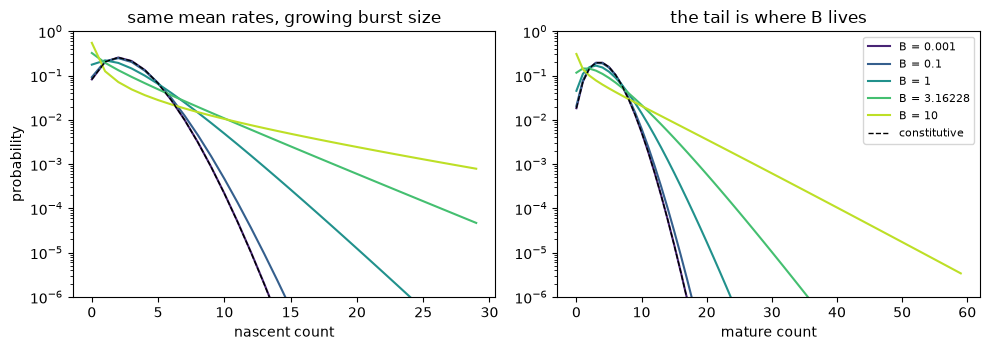

In [4]:
freq_net = CMEModel('Custom', 'None', network='0 -> B x U -> S -> 0')                       # k0 = burst frequency
mean_net = CMEModel('Custom', 'None', network='0 -> B x U -> S -> 0', burst_mean_rate=True) # k0 = mean production rate
B, k0, k1, k2 = 3.0, 0.7, 0.4, 0.25
same = np.abs(mean_net.eval_model_pss(np.log10([B, k0 * B, k1, k2]), [30, 40])
              - freq_net.eval_model_pss(np.log10([B, k0, k1, k2]), [30, 40])).max()
print(f'mean-rate form at k_mean = k_freq * B against the frequency form: max |difference| {same:.1e}')

p_const = const_net.eval_model_pss(x_const, [30, 40])
for logB in (-1.0, -2.0, -3.0):
    d = np.abs(bursty_net.eval_model_pss(np.r_[logB, x_const], [30, 40]) - p_const).max()
    print(f'bursty network at log10 B = {logB:4.1f} against the constitutive network: max |difference| {d:.1e}')
print('burst-size box of the mean-rate network (log10):', bursty_net.bio_bounds['phys_lb'][0], 'to', bursty_net.bio_bounds['phys_ub'][0])
print(mean_net.network)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for logB, c in zip((-3.0, -1.0, 0.0, 0.5, 1.0), plt.cm.viridis(np.linspace(0.1, 0.9, 5))):
    P = bursty_net.eval_model_pss(np.r_[logB, x_const], [30, 60])
    axes[0].semilogy(P.sum(1), color=c, label=f'B = {10 ** logB:g}')
    axes[1].semilogy(P.sum(0), color=c, label=f'B = {10 ** logB:g}')
P0 = const_net.eval_model_pss(x_const, [30, 60])
axes[0].semilogy(P0.sum(1), 'k--', lw=1, label='constitutive'); axes[1].semilogy(P0.sum(0), 'k--', lw=1, label='constitutive')
axes[0].set(xlabel='nascent count', ylabel='probability', ylim=(1e-6, 1), title='same mean rates, growing burst size')
axes[1].set(xlabel='mature count', ylim=(1e-6, 1), title='the tail is where B lives')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/model_comparison_burst_size.png', dpi=120); plt.show()

The mean of either count does not move with `B`; the tail does. At `B = 0.001` the curve lies on
the constitutive one, which is what makes the embedding exact, and at `B = 10` the mature count
has a ten-fold wider spread. Everything the nested test measures is in that tail.

---
## 3 · Both tests on simulated cells

Three thousand cells drawn from the built-in `Bursty` model with $b = 5$. The constitutive
model is first fitted on its own; the nested test then fits the bursty network from that
optimum with the burst size at its floor. For contrast, the same data under the non-nested
comparison of the two built-in models at their respective optima.

constitutive fit (beta, gamma): [0.105 0.06 ]   bursty fit (b, beta, gamma): [5.097 0.519 0.304]



nested test, constitutive -> bursty network (6 s):
  LR 14048.4 on 1 df, p 0; fitted B 5.10; AIC 15530 -> 1483

non-nested comparison, Bursty (a) against Constitutive (b):
  Vuong z 31.4 (BIC-corrected 31.4), p 1.2e-216, prefer 'a'; AIC 1483 vs 15530


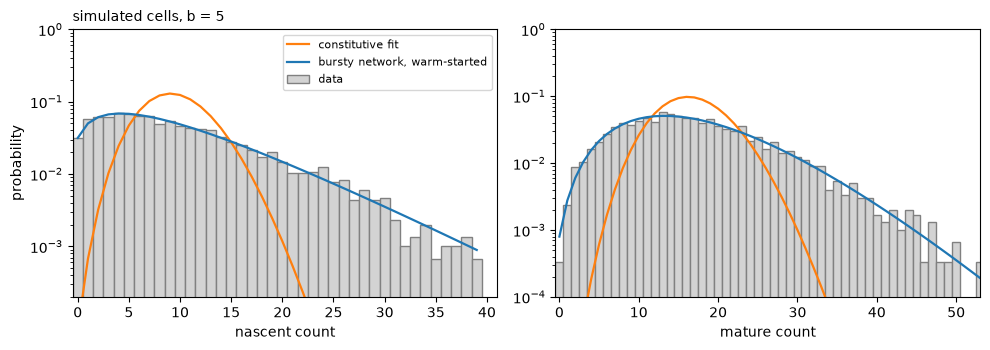

In [5]:
def draw(model, theta, limits, n, rng):
    pss = np.asarray(model.eval_model_pss(np.asarray(theta, float), list(limits)))
    flat = pss.ravel() / pss.sum()
    idx = rng.choice(flat.size, size=n, p=flat)
    return np.column_stack(np.unravel_index(idx, pss.shape))

def hist(cells):
    coords, counts = np.unique(cells, axis=0, return_counts=True)
    return coords.astype(np.int64), counts / counts.sum()

def fit(model, x0, limits, data, maxiter=100):
    res = scipy.optimize.minimize(lambda x: model.eval_model_kld_and_grad(x, limits, None, data), np.asarray(x0, float),
                                  jac=True, method='L-BFGS-B',
                                  bounds=scipy.optimize.Bounds(model.bio_bounds['phys_lb'], model.bio_bounds['phys_ub']),
                                  options=dict(maxiter=maxiter, ftol=1e-10, gtol=1e-6))
    return res.x

rng = np.random.default_rng(3)
b, beta, gamma = 5.0, 0.5, 0.3
truth = np.log10([b, beta, gamma])
lim = [40, 70]
n_sim = 3000
data_sim = hist(draw(CMEModel('Bursty', 'None'), truth, lim, n_sim, rng))

m_const, m_bursty = CMEModel('Constitutive', 'None'), CMEModel('Bursty', 'None')
x_c = fit(m_const, np.log10([beta / b, gamma / b]), lim, data_sim)        # the moment-matched start, polished
x_b = fit(m_bursty, truth + 0.2, lim, data_sim)
print('constitutive fit (beta, gamma):', np.round(10 ** x_c, 3), '  bursty fit (b, beta, gamma):', np.round(10 ** x_b, 3))

# the built-in Constitutive model is the normalised single-molecule network, so its optimum is the network's
assert np.abs(const_net.eval_model_pss(x_c, lim) - m_const.eval_model_pss(x_c, lim)).max() < 1e-9
t0 = time.time()
nested = compare_nested_models(const_net, bursty_net, None, x_c, lim, None, data_sim, n_sim, table='always', n_jobs=3)
print(f'\nnested test, constitutive -> bursty network ({time.time() - t0:.0f} s):')
print(f"  LR {nested['lr']:.1f} on {nested['df']} df, p {nested['p_lr']:.2g}; fitted B {10 ** nested['x_big'][0]:.2f}; "
      f"AIC {nested['aic_small']:.0f} -> {nested['aic_big']:.0f}")

vuong = compare_models(m_bursty, m_const, x_b, x_c, lim, None, data_sim, n_sim)
print('\nnon-nested comparison, Bursty (a) against Constitutive (b):')
print(f"  Vuong z {vuong['vuong_z']:.1f} (BIC-corrected {vuong['vuong_z_bic']:.1f}), p {vuong['p_vuong']:.2g}, prefer {vuong['prefer']!r}; "
      f"AIC {vuong['aic_a']:.0f} vs {vuong['aic_b']:.0f}")

H_sim = dense(data_sim, lim)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
plot_marginals(axes, H_sim, [m_const.eval_model_pss(x_c, lim), bursty_net.eval_model_pss(nested['x_big'], lim)],
               ['constitutive fit', 'bursty network, warm-started'], title=f'simulated cells, b = {b:g}')
plt.tight_layout(); plt.savefig('figures/model_comparison_simulated.png', dpi=120); plt.show()

The constitutive fit matches the means and nothing else: its marginals are too narrow by the
whole burst-size factor, and the data's tail is orders of magnitude above it. A likelihood ratio
of fourteen thousand nats is what that picture looks like in numbers.

Both tests agree, as they must on data this clear. Their sizes differ in kind: the likelihood
ratio measures how much better the nesting model fits, Vuong's statistic measures how
*consistently* one model beats the other across cells, in standard errors. On a nested pair the
likelihood ratio is the sharper test; Vuong's test is for pairs where no embedding exists.

---
## 4 · Is transcription bursty? A panel of 40 real genes

The GABAergic-neuron example (728 cells), 40 genes, no sequencing-noise model. The built-in
`Constitutive` model is fitted through `perform_inference` (it has a moments start); its
optimum is handed, gene by gene, to the nested test against the mean-rate bursty network, with
the genes spread over a thread pool. The built-in `Bursty` model is fitted independently as a
check: it is the same model as the mean-rate network in different units, so the two fits should
agree on the burst size and on the divergence.

The first pass uses the embedded point alone as the start (`nudge=False`), to show a trap. The
embedding puts the burst size at its floor, and for a gene with large bursts the divergence is
flat there: the gradient in `B` vanishes as `B` does, and a gradient optimiser stops where it
stands. The nesting guarantee still holds, the big model is never worse than the small one, but
it is not the optimum either. By default `compare_nested_models` therefore fits once more from
every pinned coordinate moved to the middle of its box and keeps the best (`nudge=True`);
`extra_starts` takes starts of your own, such as the big model's own moments fit.

The complementary question on one deeply sampled gene, whether an extra degradation
reaction improves on the bursty model, is `reaction_networks.ipynb` §7.

In [6]:
GABA = 'example_h5ad/gaba_example.h5ad'
if not os.path.exists(GABA) and os.path.isdir('monod_examples/sample_data/gaba_anndata'):
    chunks = sorted(Path('monod_examples/sample_data/gaba_anndata').glob('chunk_*.gz'))      # the example repo ships zlib chunks
    open(GABA, 'wb').write(b''.join(zlib.decompress(open(f, 'rb').read()) for f in chunks))
gaba = ad.read_h5ad(GABA)
gaba.var_names_make_unique()

N_PANEL = 40
GP = {'max_iterations': 150, 'num_restarts': 1}
t0 = time.time()
res_c = perform_inference(gaba, CMEModel('Constitutive', 'None'), n_genes=N_PANEL, viz=False, gradient_params=GP,
                          dataset_string='cmp_constitutive', seed=1, num_cores=N_CORES)
res_b = perform_inference(gaba, CMEModel('Bursty', 'None'), n_genes=N_PANEL, viz=False, gradient_params=GP,
                          dataset_string='cmp_bursty', seed=1, num_cores=N_CORES)
assert list(res_c.var_names) == list(res_b.var_names)
genes = list(res_c.var_names)
sd = searchdata_from_adata(res_c)
n_cells = int(sd.n_cells)
X_c = np.asarray(search_result_from_uns(res_c.uns['search_result']).phys_optimum, float)
X_b = np.asarray(search_result_from_uns(res_b.uns['search_result']).phys_optimum, float)
print(f'{N_PANEL} genes, {n_cells} cells: constitutive and bursty fits in {time.time() - t0:.0f} s')

40 genes, 728 cells: constitutive and bursty fits in 0 s


In [7]:
def nested_gene(j, nudge=True):
    lim_j, data_j = sd.M[:, j], sd.hist[j]
    r = compare_nested_models(const_net, bursty_net, None, X_c[j], lim_j, None, data_j, n_cells, table='always', maxiter=150, nudge=nudge)
    B_, k1_, k2_ = 10 ** r['x_big']
    kld_builtin = float(CMEModel('Bursty', 'None').eval_model_kld(X_b[j], lim_j, None, data_j))
    return dict(gene=genes[j], kld_const=r['kld_small'], kld_bursty=r['kld_big'], kld_bursty_builtin=kld_builtin,
                LR=r['lr'], p=r['p_lr'] / 2, B=B_, beta_over_B=k1_ / B_, gamma_over_B=k2_ / B_, b_builtin=10 ** X_b[j, 0],
                prefer_bursty=r['prefer_big'], x_big=tuple(r['x_big']))

# the p-value is halved: with B at its floor in the embedding the null distribution of the likelihood
# ratio is the half-half mixture of a point mass at zero and chi-square(1) (Self and Liang, 1987)
t0 = time.time()
with ThreadPoolExecutor(max_workers=N_CORES) as pool:
    naive = pd.DataFrame(list(pool.map(lambda j: nested_gene(j, nudge=False), range(N_PANEL)))).set_index('gene')
naive['builtin_minus_warm'] = 2 * n_cells * (naive.kld_bursty_builtin - naive.kld_bursty)
stuck = naive.index[naive.builtin_minus_warm < -10]
print(f'embedded start only ({time.time() - t0:.0f} s): the independent Bursty fit beats the warm start by more than 10 nats '
      f'on {len(stuck)} genes: {list(stuck)}')
print(naive.loc[stuck, ['kld_const', 'kld_bursty', 'kld_bursty_builtin', 'B', 'b_builtin', 'builtin_minus_warm']].round(3).to_string())

t0 = time.time()
with ThreadPoolExecutor(max_workers=N_CORES) as pool:
    panel = pd.DataFrame(list(pool.map(nested_gene, range(N_PANEL)))).set_index('gene')
panel['builtin_minus_warm'] = 2 * n_cells * (panel.kld_bursty_builtin - panel.kld_bursty)
print(f'\nwith the nudged start ({time.time() - t0:.0f} s): bursty preferred at 5 % on {int(panel.prefer_bursty.sum())} of {N_PANEL} genes; '
      f'burst size B below 1 on {int((panel.B < 1).sum())}, above 3 on {int((panel.B > 3).sum())}')
print(f'network fit against the independent built-in Bursty fit: deviance difference from '
      f'{panel.builtin_minus_warm.min():.2f} to {panel.builtin_minus_warm.max():.2f} nats (positive = the nested fit is better)')
panel.drop(columns='x_big').sort_values('LR', ascending=False).round(3)

embedded start only (37 s): the independent Bursty fit beats the warm start by more than 10 nats on 9 genes: ['Lmo7', 'Fhit', 'Mpped1', 'Shisa9', 'Cpne5', 'Efna5', 'Casc4', 'Vstm2l', 'Yjefn3']
        kld_const  kld_bursty  kld_bursty_builtin      B  b_builtin  builtin_minus_warm
gene                                                                                   
Lmo7        0.518       0.516               0.053  0.001      2.122            -674.240
Fhit        1.096       1.093               0.088  0.001      3.997           -1462.956
Mpped1      3.589       3.583               0.388  0.001     12.656           -4651.925
Shisa9      7.028       7.016               0.687  0.001     26.383           -9215.035
Cpne5       0.836       0.831               0.125  0.001      3.045           -1027.781
Efna5       6.603       6.594               0.627  0.001     21.512           -8688.870
Casc4       0.563       0.562               0.140  0.001      1.457            -614.251
Vstm2l      0.6


with the nudged start (40 s): bursty preferred at 5 % on 40 of 40 genes; burst size B below 1 on 21, above 3 on 8
network fit against the independent built-in Bursty fit: deviance difference from -0.13 to 0.03 nats (positive = the nested fit is better)


,kld_const,kld_bursty,kld_bursty_builtin,LR,p,B,beta_over_B,gamma_over_B,b_builtin,prefer_bursty,builtin_minus_warm
gene,,,,,,,,,,,
Shisa9,7.028,0.687,0.687,9232.182,0.0,26.361,0.003,0.013,26.383,True,-0.127
Efna5,6.603,0.627,0.627,8701.827,0.0,21.503,0.003,0.019,21.512,True,-0.031
Mpped1,3.589,0.388,0.388,4661.398,0.0,12.660,0.022,0.019,12.656,True,0.026
Nell2,1.308,0.111,0.111,1742.850,0.0,4.906,0.050,0.572,4.906,True,0.000
Fhit,1.096,0.088,0.088,1467.531,0.0,3.997,0.083,4.398,3.997,True,0.003
Clstn3,1.087,0.280,0.280,1174.663,0.0,2.269,0.143,0.062,2.269,True,-0.000
Cpne5,0.836,0.125,0.125,1034.849,0.0,3.046,0.629,0.373,3.045,True,-0.001
Creb3l2,0.749,0.064,0.064,996.969,0.0,3.763,0.358,0.773,3.763,True,0.003
Vstm2l,0.695,0.121,0.121,835.969,0.0,2.171,1.049,0.112,2.171,True,0.000


The mean-rate network and the built-in `Bursty` model are one model in two coordinate systems:
`B` is the burst size, and the network's `beta` and `gamma` are the built-in's divided by `b`,
because the network's time unit is the mean production time rather than the burst interval.
That is why the two burst-size columns agree once the start is right. The two passes show the
two faces of a warm start: it guarantees that the nesting model never ends worse than the small
one, and it can inherit the small model's view of the world, a burst size of nothing, on exactly
the genes where the truth is furthest from it. The nudged start costs one more fit per pinned
coordinate and closes the gap on every gene here.

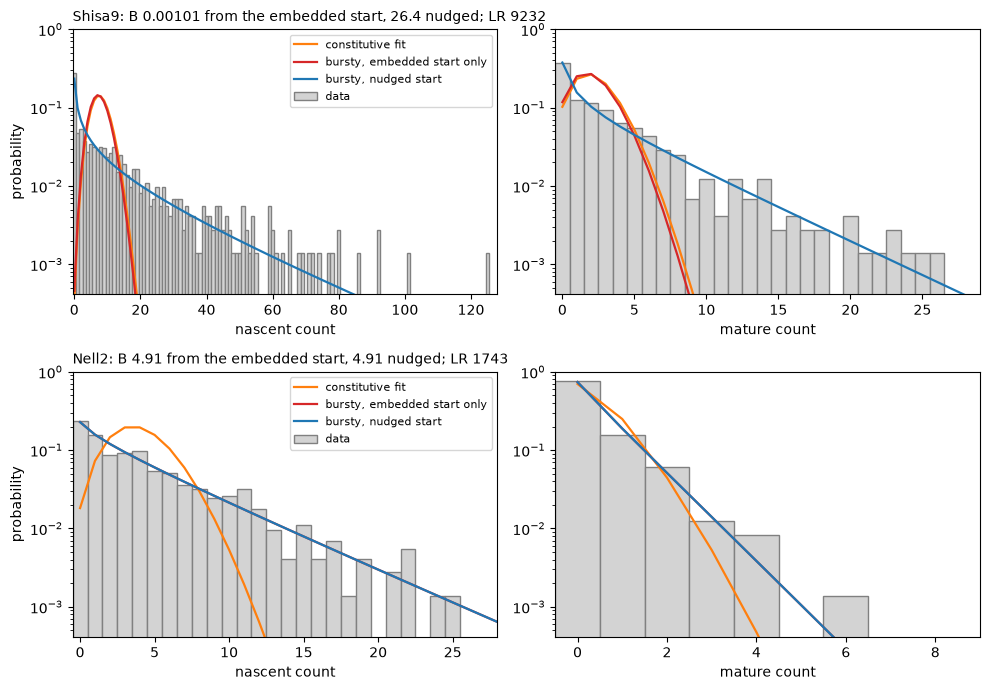

In [8]:
# the trap and its rescue on the gene where it bit hardest, and the strongest case for bursts overall
worst = naive.builtin_minus_warm.idxmin()
top = panel.LR[naive.builtin_minus_warm > -10].idxmax()           # the strongest case the embedded start handled
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, g in enumerate((worst, top)):
    j = genes.index(g)
    lim_j, H = sd.M[:, j], dense(sd.hist[j], sd.M[:, j])
    fits_g = [m_const.eval_model_pss(X_c[j], lim_j), bursty_net.eval_model_pss(np.array(naive.loc[g, 'x_big']), lim_j),
              bursty_net.eval_model_pss(np.array(panel.loc[g, 'x_big']), lim_j)]
    plot_marginals(axes[row], H, fits_g, ['constitutive fit', 'bursty, embedded start only', 'bursty, nudged start'],
                   colors=['tab:orange', 'tab:red', 'tab:blue'],
                   title=f"{g}: B {naive.loc[g, 'B']:.3g} from the embedded start, {panel.loc[g, 'B']:.3g} nudged; LR {panel.loc[g, 'LR']:.0f}")
plt.tight_layout(); plt.savefig('figures/model_comparison_trap.png', dpi=120); plt.show()

On the upper gene the red and orange curves coincide: started at the floor, the bursty network
never left the constitutive fit, although the data's tail runs an order of magnitude beyond both.
The nudged start finds the blue curve, which the independent fit also finds. The lower row is
the strongest case among the genes the embedded start handled: there the red and blue curves
coincide instead, and both leave the constitutive fit far behind.

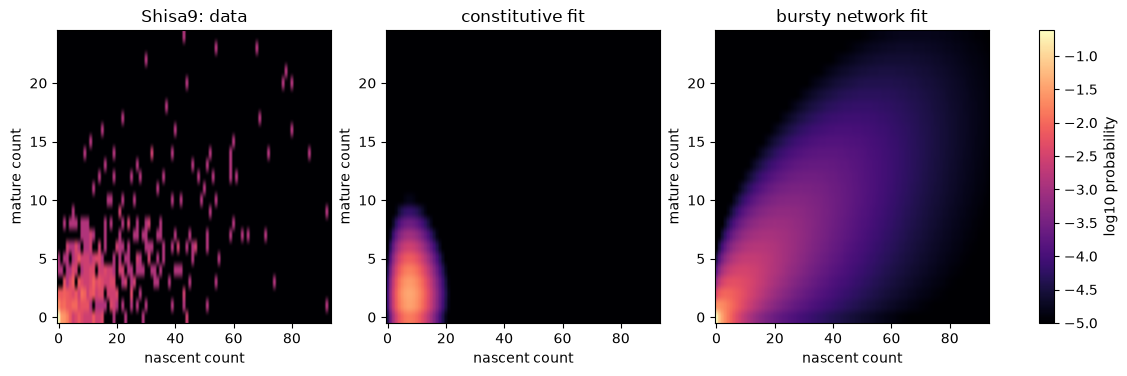

In [9]:
# the joint distribution, not just the marginals: data and the two fits for the strongest gene in the panel
best = panel.LR.idxmax()
j = genes.index(best)
lim_j, H = sd.M[:, j], dense(sd.hist[j], sd.M[:, j])
P_c, P_b = m_const.eval_model_pss(X_c[j], lim_j), bursty_net.eval_model_pss(np.array(panel.loc[best, 'x_big']), lim_j)
u_max = int(np.argmax(np.cumsum(H.sum(1)) > 0.995)) + 2
s_max = int(np.argmax(np.cumsum(H.sum(0)) > 0.995)) + 2
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
vmax = max(H.max(), P_c.max(), P_b.max())
for ax, Z, ttl in zip(axes, (H, P_c, P_b), (f'{best}: data', 'constitutive fit', 'bursty network fit')):
    im = ax.imshow(np.log10(Z[:u_max, :s_max].T + 1e-6), origin='lower', aspect='auto', cmap='magma', vmin=-5, vmax=np.log10(vmax))
    ax.set(xlabel='nascent count', ylabel='mature count', title=ttl)
plt.colorbar(im, ax=axes, label='log10 probability', fraction=0.025)
plt.savefig('figures/model_comparison_joint.png', dpi=120, bbox_inches='tight'); plt.show()

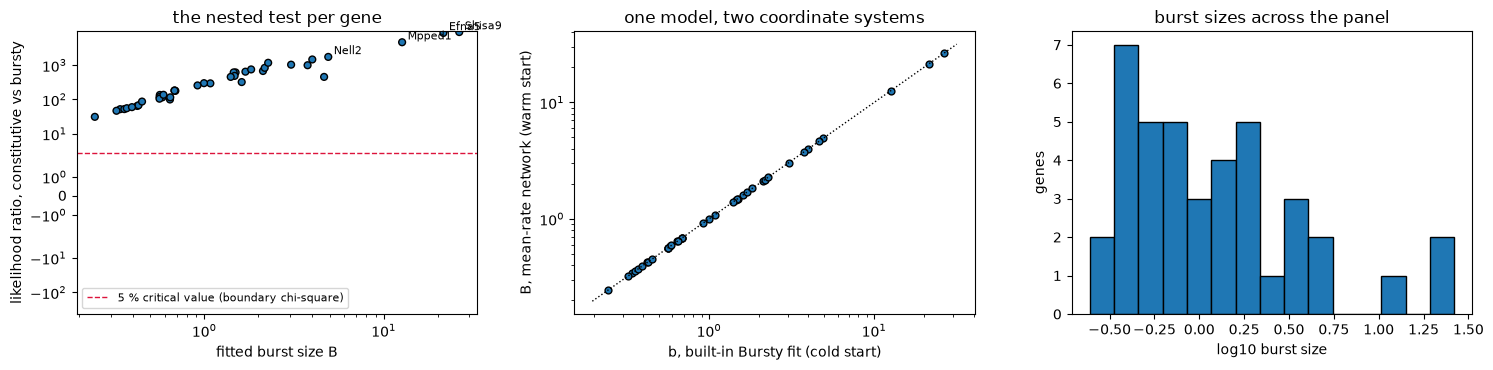

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
ax = axes[0]
ax.scatter(panel.B, panel.LR, s=24, c=np.where(panel.prefer_bursty, 'tab:blue', 'lightgray'), edgecolor='k')
ax.axhline(2.71, color='crimson', ls='--', lw=1, label='5 % critical value (boundary chi-square)')
ax.set(xscale='log', yscale='symlog', xlabel='fitted burst size B', ylabel='likelihood ratio, constitutive vs bursty', title='the nested test per gene')
ax.legend(fontsize=8)
for g in panel.index[panel.LR > panel.LR.quantile(0.9)]:
    ax.annotate(g, (panel.B[g], panel.LR[g]), fontsize=8, xytext=(4, 2), textcoords='offset points')
ax = axes[1]
ax.scatter(panel.b_builtin, panel.B, s=24, c='tab:blue', edgecolor='k')
lims = [min(panel.B.min(), panel.b_builtin.min()) * 0.8, max(panel.B.max(), panel.b_builtin.max()) * 1.2]
ax.plot(lims, lims, 'k:', lw=1)
ax.set(xscale='log', yscale='log', xlabel='b, built-in Bursty fit (cold start)', ylabel='B, mean-rate network (warm start)', title='one model, two coordinate systems')
ax = axes[2]
ax.hist(np.log10(panel.B), bins=15, color='tab:blue', edgecolor='k')
ax.set(xlabel='log10 burst size', ylabel='genes', title='burst sizes across the panel')
plt.tight_layout(); plt.savefig('figures/model_comparison_bursty_panel.png', dpi=120); plt.show()

---
## 5 · A pair that does not nest: exponential against deterministic lifetime

The `Delay` model keeps the bursty production and the splicing step but gives the mature RNA
a fixed lifetime instead of an exponential one. Neither model is a point of the other's
parameter space, so there is no warm start and no likelihood-ratio test; `compare_models`
takes the two optima and asks, cell by cell, which model explains the counts better. Vuong's
statistic is the mean log-likelihood ratio in units of its standard error, positive when the
first model wins, with a Schwarz correction for the parameter counts (equal here).

In [11]:
t0 = time.time()
res_d = perform_inference(gaba, CMEModel('Delay', 'None'), n_genes=N_PANEL, viz=False, gradient_params=GP,
                          dataset_string='cmp_delay', seed=1, num_cores=N_CORES)
assert list(res_d.var_names) == genes
X_d = np.asarray(search_result_from_uns(res_d.uns['search_result']).phys_optimum, float)
m_b, m_d = CMEModel('Bursty', 'None'), CMEModel('Delay', 'None')
rows = []
for j, g in enumerate(genes):
    r = compare_models(m_b, m_d, X_b[j], X_d[j], sd.M[:, j], None, sd.hist[j], n_cells)
    rows.append(dict(gene=g, kld_bursty=r['kld_a'], kld_delay=r['kld_b'], delta_AIC=r['aic_b'] - r['aic_a'],
                     vuong_z=r['vuong_z'], p=r['p_vuong'], prefer=r['prefer']))
nonnested = pd.DataFrame(rows).set_index('gene')
print(f'Delay fits and comparisons in {time.time() - t0:.0f} s')
print('preferred at 5 %:', nonnested.prefer.map({'a': 'Bursty', 'b': 'Delay', None: 'neither'}).value_counts().to_dict())
nonnested.sort_values('vuong_z').round(3)

Delay fits and comparisons in 0 s
preferred at 5 %: {'neither': 31, 'Bursty': 7, 'Delay': 2}


,kld_bursty,kld_delay,delta_AIC,vuong_z,p,prefer
gene,,,,,,
Vstm2l,0.121,0.107,-19.992,-2.278,0.023,b
Ppp6c,0.080,0.073,-10.059,-2.065,0.039,b
Clstn3,0.280,0.267,-19.172,-1.790,0.073,None
Cpne5,0.125,0.116,-13.432,-1.762,0.078,None
Rabepk,0.029,0.026,-4.072,-1.759,0.079,None
Clptm1,0.044,0.038,-8.056,-1.734,0.083,None
Wwp1,0.089,0.085,-5.804,-1.513,0.130,None
Mpped1,0.388,0.379,-12.629,-1.456,0.145,None
Fam193a,0.129,0.128,-1.950,-1.160,0.246,None


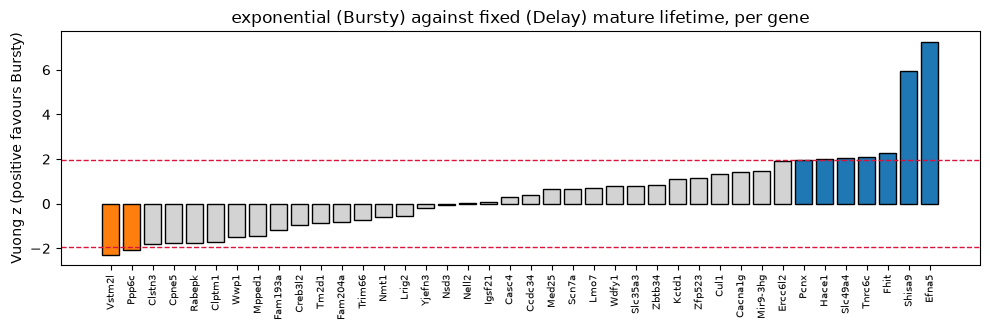

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.4))
order = nonnested.sort_values('vuong_z')
colors = np.where(order.prefer == 'a', 'tab:blue', np.where(order.prefer == 'b', 'tab:orange', 'lightgray'))
ax.bar(range(len(order)), order.vuong_z, color=colors, edgecolor='k')
ax.axhline(1.96, color='crimson', ls='--', lw=1); ax.axhline(-1.96, color='crimson', ls='--', lw=1)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order.index, rotation=90, fontsize=7)
ax.set(ylabel='Vuong z (positive favours Bursty)', title='exponential (Bursty) against fixed (Delay) mature lifetime, per gene')
plt.tight_layout(); plt.savefig('figures/model_comparison_vuong.png', dpi=120); plt.show()

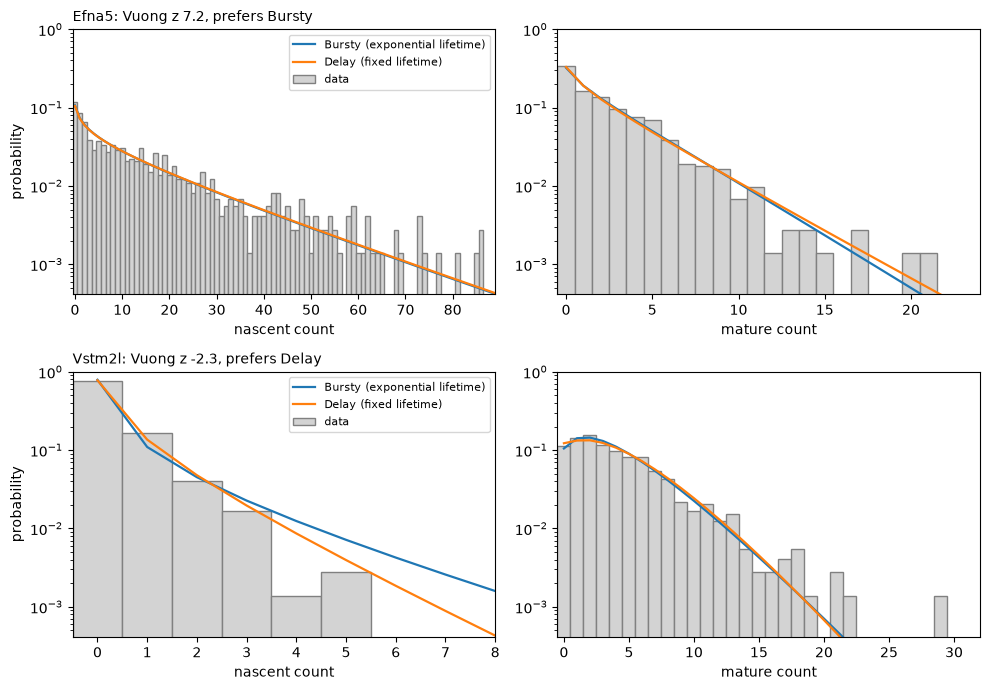

In [13]:
# the strongest gene each way: an exponential and a fixed mature lifetime against the data
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, g in enumerate((nonnested.vuong_z.idxmax(), nonnested.vuong_z.idxmin())):
    j = genes.index(g)
    lim_j, H = sd.M[:, j], dense(sd.hist[j], sd.M[:, j])
    plot_marginals(axes[row], H, [m_b.eval_model_pss(X_b[j], lim_j), m_d.eval_model_pss(X_d[j], lim_j)],
                   ['Bursty (exponential lifetime)', 'Delay (fixed lifetime)'], colors=['tab:blue', 'tab:orange'],
                   title=f"{g}: Vuong z {nonnested.loc[g, 'vuong_z']:.1f}, prefers {'Bursty' if nonnested.loc[g, 'vuong_z'] > 0 else 'Delay'}")
plt.tight_layout(); plt.savefig('figures/model_comparison_lifetimes.png', dpi=120); plt.show()

A fixed lifetime gives the mature count a lighter tail than an exponential one at the same mean,
so the two curves separate only in the tail and only on genes with enough counts there. That is
why most of the panel cannot tell them apart, and why a test that can return "neither" is the
right one for this question.

Most genes sit between the dashed lines: with 728 cells and small counts the two lifetime
distributions are hard to tell apart, and the honest answer is "neither". That is the point of
a test that can say so; a bare AIC difference always picks a winner.

---
## Summary

- `nesting_embedding` says whether two `CMEModel`s nest and gives the embedding; `compare_nested_models(..., embed=None)` uses it, and the warm start guarantees the big model never fits worse.
- To test for bursty transcription, write constitutive and bursty as reaction networks with `burst_mean_rate=True`; the built-in pair is not nested because of its time units.
- When the extra parameter starts at a bound, use `table="always"` and halve the chi-square p-value.
- `compare_models` handles pairs that do not nest with AIC, BIC and Vuong's test, and can return "neither".
- The chromatin notebook applies the same tests to the rule-by-emission question on a multiome dataset.